# Trabajo Práctico  - Calibración y Pose de la Cámara

## Resolución

## GRUPO: Los Unitarios

# Integrantes
1. Mariano Papaleo, LU: 848/21

2. Lucila Echegaray, LU: 561/23

3. Gastón Guzman, LU: 61/22

4. Ezequiel Flores, LU: 918/23

In [1]:
import alc
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd

### Ejercicio 1 - DLT ecuaciones formales

Siendo $Q\in \mathbb{R}^{2n\times 12}$, ¿qué rango debe tener para asegurar una solución no nula única a menos de un factor de escala? ¿Cuántos puntos, como mínimo, aseguran la solución y qué condición deben cumplir?

Encontrar el vector $\mathbf{m}$ que resuelve la minimización de la ecuación 6.

1. a) Sabemos que $Rango(Q) = dim(Im(Q))$
Por Teorema de la Dimensión:  \
$dim(Nu(Q))  + dim(Im(Q)) = n$, donde $n = Col(Q)$ \
$dim(Nu(Q))  + Rango(Q) = 12$ \
$Rango(Q) = 12 - dim(Nu(Q))$ \
Por ejemplo, si $ m = (2, 4) ⟹ 2 (1, 2)$ entonces $2$ es el factor de escala.
No puede ocurrir que el $Nu(Q) = \left\{ (1, 0) , (0, 1)\right\}$ porque entonces hay más de un factor de escala ya que podemos representar el $Nu(Q)$ como $a(1, 0) + b(0,1)$ siendo $a$ y $b$ los factores de escala.
Ademas, $m \neq 0$ porque necesitamos una solución no nula.
Por lo tanto, $dim(Nu(Q)) = 1$, siendo la cuenta final: \
$Rango(Q) = 12 - dim(Nu(Q)) = 12 - 1 = 11$ \
Por otra parte, sabemos que $Rango(Q) \leq min(Filas(Q),\ Columnas(Q))$ con $Filas(Q) = 2n$, $Columnas(Q) = 12$ \
$Rango(Q) \leq min(2n, 12)$ \
$11 \leq min(2n, 12)$ \
$11 \leq 2n$ \
$5,5 \leq n ⟹ n   ≥  6$  
Como minimo van a ser necesarios 6 puntos para asegurar la solución. \
Finalmente, los puntos $P_i = (U_i, V_i, W_i, 1)$ no deben ser coplanares, ya que si lo fueran pertenecerían a un mismo plano,
por tanto existiría un vector $V = (a, b, c, d)$ no nulo tal que $P_i  V$ daría $0$ para todo $i$. \
Lo fuerte de esto es que un solo vector $V$ anula los puntos $P_i\ \forall i$.
Por lo tanto, existen 3 formas de escribir el vector $m \in \mathbb{R}^{12}$  de manera que $Qm = 0$.
Tenemos que los vectores (de 12 coordenadas) $z_1 = (v, \mathbf{0}, \mathbf{0})$, $z_2 = (\mathbf{0}, v, \mathbf{0})$y $z_3 = (\mathbf{0}, \mathbf{0}, v)$
(donde $\mathbf{0} = (0, 0, 0, 0)$) pertenecerían al núcleo de $Q$, ya que $Qz_1 = 0$, $Qz_2 = 0$ y $Qz_3 = 0$.
Lo que implicaría que $dim(Nu(Q)) \geq 3$ y entonces el rango de $Q$ sería 9, que es menor a 11. Entonces, hay infinitas soluciones no nulas.

1) b) Queremos minimizar $||Qm||^2$ y como $Q=UΣV^T$ reescribimos $||Qm||^2=||UΣV^Tm||^2$ como $U$ es ortogonal, no modifica a la norma $ ⟹ ||UΣV^Tm||^2=||Σ(V^Tm)||^2$ \
  Llamamos $y=V^Tm ∈ R^{12}$ y como $V$ tambien es ortogonal, $||y||=||V^Tm||=||m||=1$, entonces queda minimizar: $||Σy||^2=Σ_{i=1}^{12} σ_i^2 y_i^2$ \
Como $σ_{12}$ es el menor valor singular queda acotado: \
$Σ_{i=1}^{12} σ_i^2y_i^2 \geq σ_{12}^2 Σ_{i=1}^{12}y_i^2=σ_{12}^2||y||^2=σ_{12}^2$ \
Este minimo se alcanza si tomamos $y=e_{12}=(0,0,...,1)$ y como $y=V^Tm⟹ Vy=m ⟹ Ve_{12}=v_{12}=m$ \
Luego, $m$ es el autovector asociado al menor autovalor de la matriz simétrica $Q^TQ$

---


### Ejercicio 2 - Calibración con puntos 3D

a) Utilizando los datos de la carpeta $\texttt{calib/3d}$ calcular $\mathbf{R}$,  $\mathbf{t}$ y $\mathbf{K}$.

In [66]:
todosLosPuntos2D = np.loadtxt('calib/3d/detected_corners.txt',delimiter=',')
puntos3D = np.loadtxt('calib/3d/p_W_corners.txt')

# Extraemos solo la primera fila (correspondiente a img_0001.jpg)
# y la redimensionamos a una matriz de 12 filas x 2 columnas (u, v)
puntos2D = todosLosPuntos2D[0].reshape(12, 2)

Q = alc.obtenerQ3d(puntos2D, puntos3D)

M = alc.resolverDLT3D(Q)

R, t, K = alc.devolverMatricesCalibracion3d(M, restriccion_escala=False)

# deberiamos printear las matrices calculadas?

FileNotFoundError: calib/3d/detected_corners.txt not found.

Calcular un nuevo set de parámetros para

b) $\alpha_u = \alpha_v$

c) $K_{12}=0$



In [ ]:
R_rest, t_rest, K_rest = alc.devolverMatricesCalibracion3d(M, restriccion_escala=True)

### Ejercicio 3 - Calibración con puntos coplanares

Resolver la calibración para el caso de puntos coplanares, trabajando sobre los datos de la carpeta $\texttt{calib/coplanar}$ con las imágenes $\texttt{Im\_R\_1.png}$ a $\texttt{Im\_R\_20.png}$.


a) Obtener la matriz $\mathbf{K}$

b) Encontrar la pose de $\texttt{Im\_R\_1.png}$, $\texttt{Im\_R\_10.png}$ y $\texttt{Im\_R\_20.png}$.

### Ejercicio 4 - Fútbol

a) Calcular la homografía de la cancha de futbol de la foto de $\texttt{gol-enzo.png}$. Encontrar la distancia a la que se encontraba Enzo.
    Dibujar sobre la fotografía círculos de 1 metro de diámetro alrededor de los jugadores argentinos.

La foto que nos piden evaluar es $\texttt{gol-enzo.png}$. 

Asi que empezamos por cargar la imagen y visualizarla:

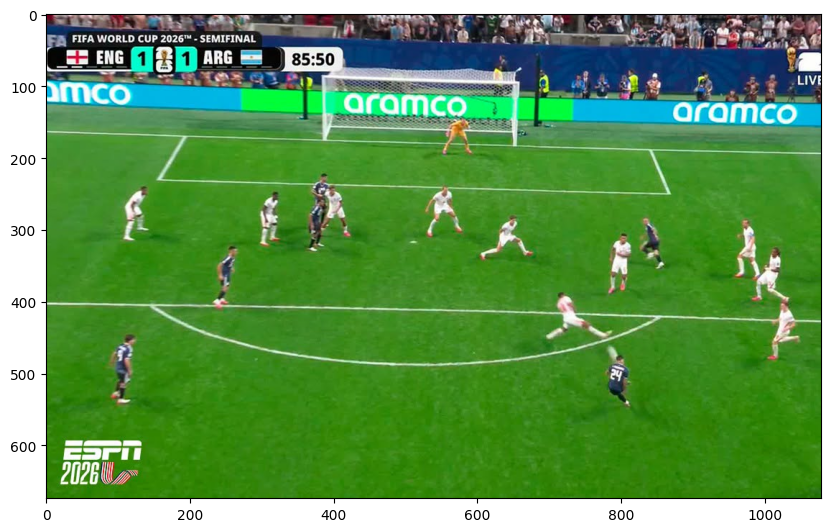

In [3]:
# Cargamos la imagen
imagenEnzo = mpimg.imread("futbol/test-gol-enzo.png")
plt.figure(figsize=(10, 10))
plt.imshow(imagenEnzo)

Para calcular la distancia en línea recta, medida sobre el piso, a la que se encuentra Enzo de la línea del arco necesitamos obtener las coordenadas de la cancha y de la imagen.

En la foto $\texttt{estadio-azteca.png}$. tenemos la medidas reales de la cancha, mientras que de la imagen anterior sacamos las coordenadas en pixeles.

Dimensiones de la imagen: (674, 1079, 4)


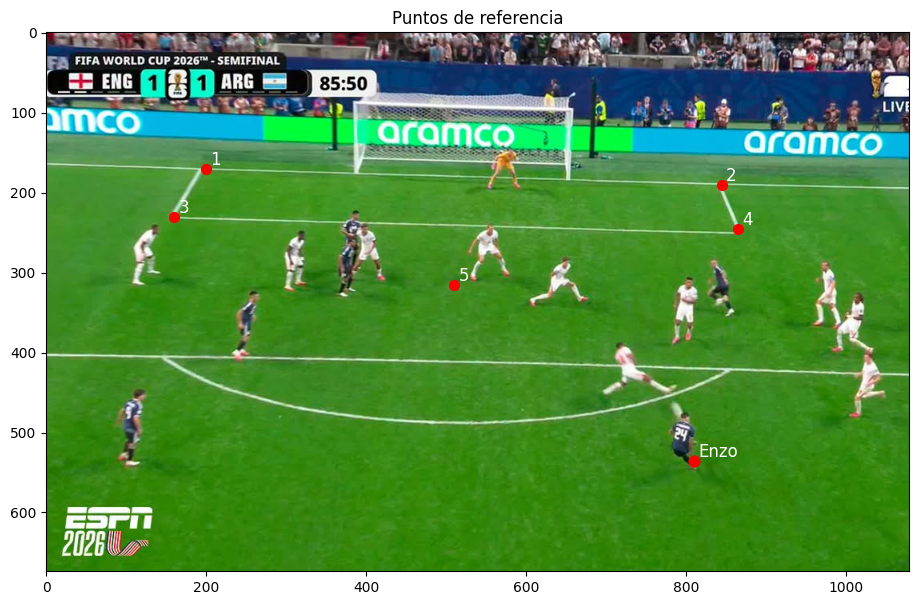

In [ ]:
# Coordenadas reales (U, V) de la cancha
U_cancha = 105  # Largo total de la cancha
V_cancha = 68   # Ancho total de la cancha
U_grande = 16.5 # Largo del Area Grande
V_grande = 40.32 #Ancho del Area Grande
U_chica = 5.5   # Largo del area chica
V_chica = 18.32 # Ancho del area chica
U_penal = 11    

V1 = (V_cancha - V_chica) / 2  # = 24.84
punto1Cancha = np.array([0, V1])  # (0, 24.84): esquina izquierda sobre la linea de fondo 

V2 = V1 + V_chica  # = 43.16
punto2Cancha = np.array([0, V2])  # (0, 43.16): esquina derecha sobre la linea de fondo 

U3 = U_chica  # = 5.5
punto3Cancha = np.array([U3, V1])  # (5.5, 24.84): esquina izquierda del borde frontal del area chica

# Cuarta 
punto4Cancha = np.array([U3, V2])  # (5.5, 43.16): esquina derecha del borde frontal del area chica

V_penal = V_cancha / 2
punto5Cancha = np.array([U_penal, V_penal])  # (11, 34): punto penal


objPts = np.array([
    punto1Cancha,
    punto2Cancha,
    punto3Cancha,
    punto4Cancha,
    punto5Cancha
], dtype=float)

# Coordenadas (u, v) de la imagen

print("Dimensiones de la imagen:", imagenEnzo.shape)

punto1Img = np.array([200, 170])  # Esquina izquierda sobre la línea de fondo
punto2Img = np.array([845, 190])  # Esquina derecha sobre la línea de fondo
punto3Img = np.array([160, 230])  # Esquina izquierda del borde frontal
punto4Img = np.array([865, 245])  # Esquina derecha del borde frontal
punto5Img = np.array([510,315]) # Punto penal

imgPts = np.array([
    punto1Img,
    punto2Img,
    punto3Img,
    punto4Img,
    punto5Img
], dtype=float)

# Coordenadas de los pies de enzo
piesEnzoImg = np.array([810, 535])

# Dibujamos los puntos en la imagen para ver su ubicacion
plt.figure(figsize=(12, 7))
plt.imshow(imagenEnzo)

for i, punto in enumerate(imgPts):
    plt.scatter(punto[0], punto[1], color="red", s=50)
    plt.text(punto[0] + 5, punto[1] - 5, str(i + 1),
             color="white", fontsize=12)
plt.scatter(piesEnzoImg[0], piesEnzoImg[1], color="red", s=60)
plt.text(piesEnzoImg[0] + 5, piesEnzoImg[1] - 5, "Enzo",
             color="white", fontsize=12)
plt.title("Puntos de referencia")
plt.show()

Ahora bien, nuestro primer objetivo fue llevar los pies del jugador a la cancha, es decir, queremos pasar de coordenadas de la imagen $(u,v)$ a coordenadas de la cancha $(U,V)$.

Para lograr esto necesitamos $H^{-1}$, por lo tanto, creamos la funcion `calcularHomografia2D(imgPts, objPts)` para obtener la homografia $H$. Dentro de la funcion, utilizamos `obtenerQ2d` creada anteriormente para obtener la matriz $Q$, despues resolvimos $Qh = 0$ mediante SVD, donde nos quedamos con la ultima columna de $V$ ya que este es el vector asociado al menor valor singular. 

Este vector es la solucion porque buscamos un vector h que, al multiplicarlo por Q, produzca un resultado lo más cercano posible al vector nulo:

$$
\min_{\substack{\|h\|=1}} \|Qh\|^2
$$

In [5]:
# Calculamos la Homografia
H = alc.calcularHomografia2D(imgPts, objPts)
print("Homografía H:")
print(H)


Homografía H:
[[-1.08056263e+01  4.01011059e+01 -7.81285507e+02]
 [ 7.91489095e+00  1.60831073e+00  1.42134001e+02]
 [-1.72672736e-02  2.87027424e-03  1.00000000e+00]]


Ahora que tenemos la matriz $H$, tambien tenemos $H^{-1}$ que es simplemente aplicar la inversa a la homografia. Creamos la funcion `proyectarAPuntoReal(H, imgPts)` que hace el paso de coordenadas de la imagen a coordenadas del mundo real: 

$$
H^{-1}
\begin{bmatrix}
u\\
v\\
1
\end{bmatrix}
=
\begin{bmatrix}
U\\
V\\
1
\end{bmatrix}
$$


In [ ]:
# Transformamos los pies a coordenadas de la cancha para verificar la posicion de Enzo
U_enzo, V_enzo = alc.proyectarAPuntoReal(H, piesEnzoImg)

print("Posición de Enzo en la cancha:")
print(f"U = {U_enzo:.2f} metros")
print(f"V = {V_enzo:.2f} metros")

Posición de Enzo en la cancha:
U = 22.73 metros
V = 40.21 metros



Queda ver su distancia a la linea del arco.

Teniendo en cuenta las medidas de la imagen `estadio_azteca.png`, un arco se ubica sobre $U = 105 m$ con $V = 7,32 m$ centrado en la linea de meta. La funcion `distanciaPiesArco(H, imgPts)` calcula donde se ubica cada palo teniendo en cuenta estos datos y mediante la distancia euclidea obtiene la distancia, sobre el piso, desde los pies del jugador hasta el arco:

$$
\sqrt{(U-U_{\text{cancha}})^2+(V-V_{\text{cercano}})^2}
$$

siendo $U$ y $V$ los pies de enzo, $Ucancha$ la ubicacion $U$ del arco y $Vcercano$ el punto del arco mas cercano al jugador.

In [7]:
distancia = alc.distanciaPiesArco(H, piesEnzoImg)

print(f"Distancia de los pies de Enzo al arco: {distancia:.2f} metros")

Distancia de los pies de Enzo al arco: 22.88 metros


Pasando al punto $b)$, como queremos dibujar un circulo sobre el piso en cada jugador argentino, debemos ubicar primero a esos jugadores en la imagen.

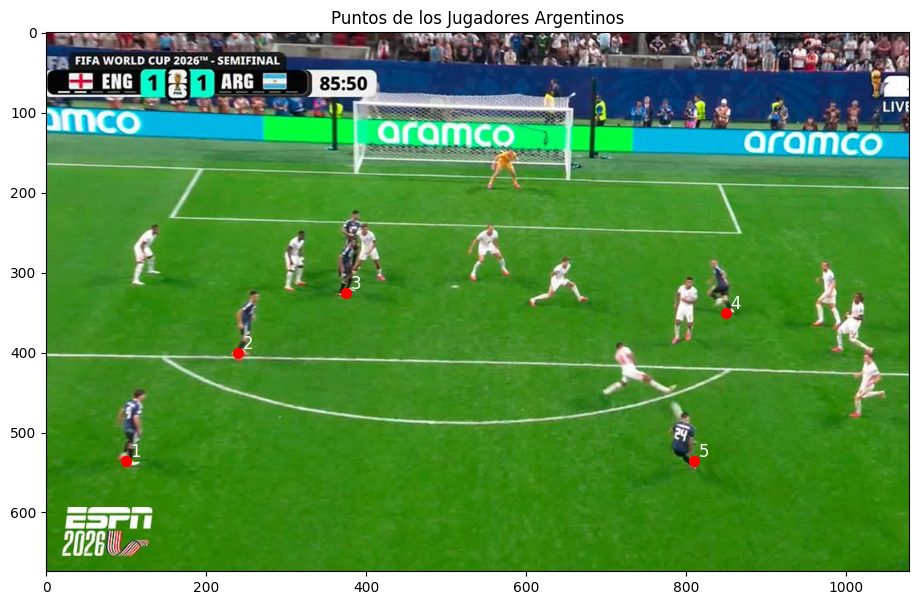

In [ ]:
# Coordenadas (u, v) de cada jugador argentino en la imagen
puntoJug1Img = np.array([100, 535])  
puntoJug2Img = np.array([240, 400])  
puntoJug3Img = np.array([375, 325])  
puntoJug4Img = np.array([850, 350])  
puntoJug5Img = np.array([810, 535]) # Coordenadas de los pies de enzo

imgPtsJug = np.array([
    puntoJug1Img,
    puntoJug2Img,
    puntoJug3Img,
    puntoJug4Img,
    puntoJug5Img
], dtype=float)

# Dibujamos los puntos en la imagen para ver su ubicacion
plt.figure(figsize=(12, 7))
plt.imshow(imagenEnzo)

for i, punto in enumerate(imgPtsJug):
    plt.scatter(punto[0], punto[1], color="red", s=50)
    plt.text(punto[0] + 5, punto[1] - 5, str(i + 1),
             color="white", fontsize=12)
    
plt.title("Puntos de los Jugadores Argentinos")
plt.show()

Para resolver el ejercicio pasamos a crear la funcion `dibujarCirculosJugadores(H, jugPts)`.

Dentro de ella, empezamos proyectando cada coordenada de los jugadores de la imagen $(u, v)$ a coordenadas de la cancha $(U, V)$, mediante la funcion `proyectarAPuntoReal(H, imgPts)` creada anteriormente.

Una vez que tenemos la posicion de un jugador (Ui,Vi) definimos un circulo con los calculos:

$$
\begin{aligned}
U &= U_i + \cos(\theta)\\[6pt]
V &= V_i + \sin(\theta)
\end{aligned}
$$

porque $(U-Ui)^2 + (V-Vi)^2 = 1$, es decir, la parametrizacion corresponde a un círculo de radio 1 metro.

Luego proyectamos los puntos de esos circulos a la imagen mediante la funcion `proyectarAPuntoImagen(H, objPt)`, que realizamos en base a la ecuacion: 

$$
\lambda
\begin{bmatrix}
u\\
v\\
1
\end{bmatrix}
=
H
\begin{bmatrix}
U\\
V\\
1
\end{bmatrix}
$$

Por ultimo, dibujamos los circulos proyectados sobre la imagen


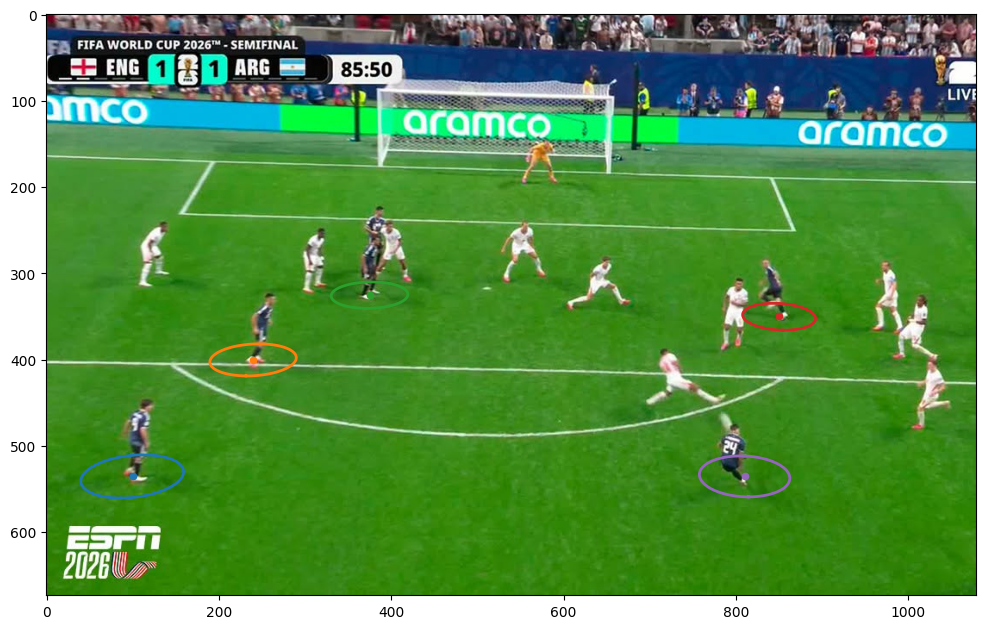

La posicion del jugador 0 es: (22.79,27.33)
La posicion del jugador 1 es: (16.51,28.70)
La posicion del jugador 2 es: (11.97,30.96)
La posicion del jugador 3 es: (13.08,41.97)
La posicion del jugador 4 es: (22.73,40.21)


In [ ]:
# Cargamos la imagen de Enzo
imagenEnzo = mpimg.imread("futbol/test-gol-enzo.png")

plt.figure(figsize=(12, 8))
plt.imshow(imagenEnzo)

# Dibujamos los circulos de cada jugador argentino
posiciones = alc.dibujarCirculosJugadores(H, imgPtsJug)
for i, pos in enumerate(posiciones):
    print(f"La posicion del jugador {i} es: ({pos[0]:.2f},{pos[1]:.2f})")

b) Calcular la homografía de la changa de fútbol de la foto $\texttt{posibleoffside.jpg}$.
    Trazar sobre la fotografía una recta sobre el pié del jugador del equipo defensor que defina si hay fuera de juego.
    

La idea para resolver el ejercicio es definir la recta en coordenadas de la cancha y luego proyectarlo a la imagen.

Empezamos evaluando la imagen $\texttt{test-fuera-de-juego.png}$

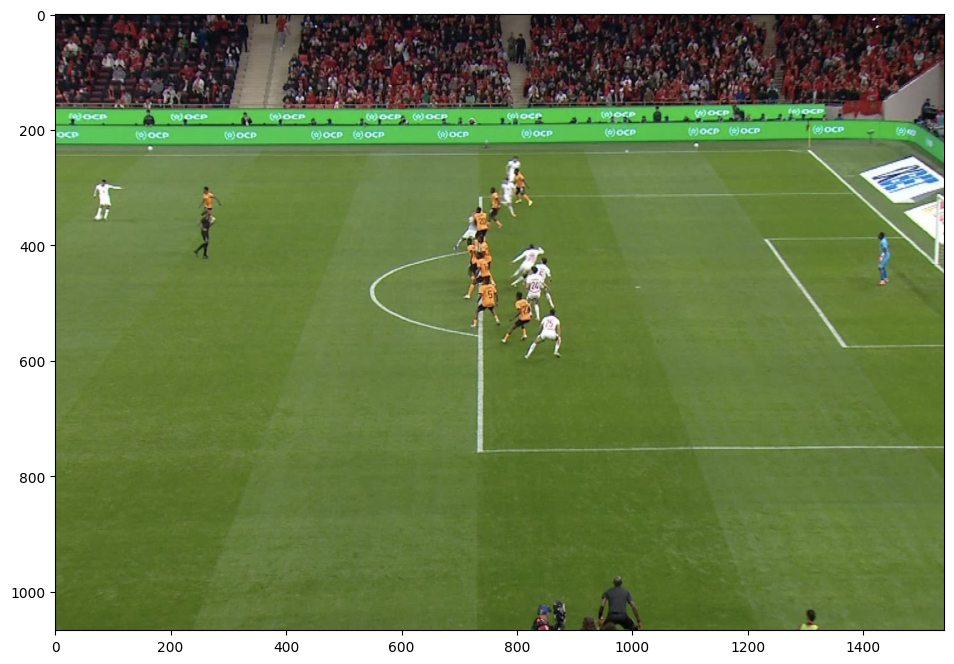

In [2]:
# Cargamos la imagen
imagenFuera = mpimg.imread("futbol/test-fuera-de-juego.png")

# La mostramos
plt.figure(figsize=(12, 8))
plt.imshow(imagenFuera)


El primer objetivo es poder identificar el pie del ultimo defensor en coordenadas reales $(Ud, Vd)$, para ello, necesitamos identificar los puntos de referencia de la cancha y la imagen para asi, generar la Homografia $H$

Dimensiones de la imagen: (1067, 1541, 3)


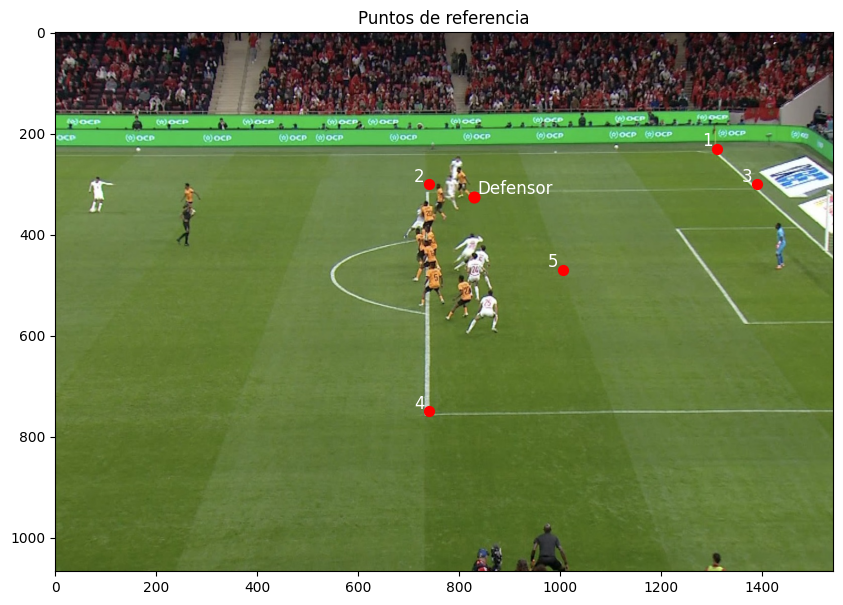

In [3]:
# Coordenadas reales (U, V) de la cancha
U_cancha = 105  # Largo total de la cancha
V_cancha = 68   # Ancho total de la cancha
U_grande = 16.5 # Largo del Area Grande
V_grande = 40.32 #Ancho del Area Grande
U_chica = 5.5   # Largo del area chica
V_chica = 18.32 # Ancho del area chica
U_penal = 11    

# Puntos de la cancha del arco derecho

punto1Cancha = np.array([U_cancha, V_cancha])  # (105, 68): Esquina superior derecha sobre la linea del fondo

U2 = U_cancha - U_grande # 88.5
V2 = (V_cancha + V_grande) / 2 # = 54.16
punto2Cancha = np.array([U2, V2])  # (88.5, 54.16): Esquina superior izquierda del area grande

punto3Cancha = np.array([U_cancha, V2])  # (105, 54.16 ): Esquina superior derecha del area grande

V4 = (V_cancha - V_grande) / 2 # = 13.84
punto4Cancha = np.array([U2, V4])  # (88.5, 13.84): Esquina inferior izquierda del area grande

U5 = U_cancha - U_penal # = 94
V_penal = V_cancha / 2  # = 34
punto5Cancha = np.array([U5 ,V_penal ])  # (94, 34): Punto penal

objPts = np.array([
    punto1Cancha,
    punto2Cancha,
    punto3Cancha,
    punto4Cancha,
    punto5Cancha
], dtype=float)

# Coordenadas (u, v) de la imagen

print("Dimensiones de la imagen:", imagenFuera.shape)

punto1Img = np.array([1310,230 ])  # Esquina superior derecha sobre la linea del fondo
punto2Img = np.array([740,300 ])  # Esquina superior izquierda del area grande
punto3Img = np.array([1390,300])  # Esquina superior derecha del area grande
punto4Img = np.array([740,750 ])  # Esquina inferior izquierda del area grande
punto5Img = np.array([1005,470]) # Punto penal

imgPts = np.array([
    punto1Img,
    punto2Img,
    punto3Img,
    punto4Img,
    punto5Img,
], dtype=float)

# Coordenadas de los pies del ultimo defensor
puntoDefensorImg = np.array([830,325])

# Dibujamos los puntos en la imagen para ver su ubicacion
plt.figure(figsize=(12, 7))
plt.imshow(imagenFuera)

for i, punto in enumerate(imgPts):
    plt.scatter(punto[0], punto[1], color="red", s=50)
    plt.text(punto[0] - 30, punto[1] - 5, str(i + 1),
             color="white", fontsize=12)
    
plt.scatter(puntoDefensorImg[0], puntoDefensorImg[1], color="red", s=60)
plt.text(puntoDefensorImg[0] + 5, puntoDefensorImg[1] - 5, "Defensor",
             color="white", fontsize=12)


plt.title("Puntos de referencia")
plt.show()

Estimamos la homografia $H$ para la imagen, luego, proyectamos la posicion del ultimo defensor de coordenadas $(ud, vd)$  a coordenadas de cancha $(Ud, Vd)$

In [ ]:
H = alc.calcularHomografia2D(imgPts, objPts)
print("Homografia H:")
print(H)

# Obtenemos las coordenadas de cancha del defensor
Ud, Vd = alc.proyectarAPuntoReal(H, puntoDefensorImg)
print(f"Coordenadas de cancha del ultimo defensor: ({Ud:.2f}, {Vd:.2f})")

Homografía H:
[[ 8.17971042e+01  1.60380865e+01 -6.55355788e+03]
 [ 2.05789628e-01 -7.14719454e+00  1.00328621e+03]
 [-7.31191637e-04  2.15344890e-02  1.00000000e+00]]
Coordenadas de cancha del ultimo defensor: (90.73, 50.79)


Continuamos construyendo una recta paralela a la linea de fondo que pase por ese punto. Para eso creamos la funcion `generarRectaCancha(Ud, cantidad=100)` que utiliza la coordenada $Ud$ calculada antes y devuelve un array que representa la linea de offside tomando en cuenta la posicion del defensor.

Una vez creada la recta, la proyectamos a coordenadas de la imagen y hacemos la comparacion con los pies de los rivales.

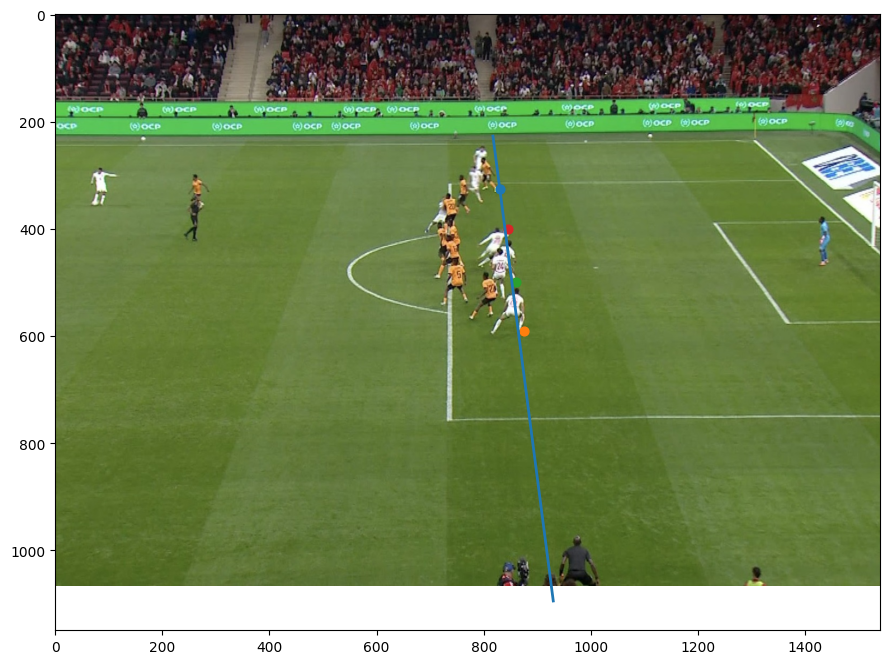

In [5]:
# Generamos la recta paralela a la linea de fondo que pasa por el defensor
rectaCancha = alc.generarRectaCancha(Ud)

# Proyectamos la recta a las coordenadas de la imagen
rectaImagen = alc.proyectarRectaImagen(H, rectaCancha)

# Mostramos la imagen
plt.figure(figsize=(12, 8))
plt.imshow(imagenFuera)

# Dibujamos la recta sobre la imagen
plt.plot(rectaImagen[:, 0], rectaImagen[:, 1], linewidth=2)

# Marcamos los pies del ultimo defensor
plt.scatter(puntoDefensorImg[0], puntoDefensorImg[1], s=40)

# Coordenadas de los rivales
punto1rivalImg = np.array([875, 590])
punto2rivalImg = np.array([860, 500])
punto3rivalImg = np.array([845,400])

puntosRivalesImg = np.array([
    punto1rivalImg,
    punto2rivalImg,
    punto3rivalImg
])

# Marcamos los pies de los jugadores rivales
for punto in puntosRivalesImg:
    plt.scatter(punto[0], punto[1], s=40)

plt.show()

Por ultimo, analizamos si los jugadores rivales estan realmente adelantados. 

Para ello, creamos la funcion `analizarPosiciones(H, puntoDefensorImg, puntosRivalesImg, atacaHaciaUPositivo=True)` que compara las posiciones de los jugadores rivales con el ultimo defensor. Dentro de la funcion proyectamos los puntos de estos jugadores a la cancha y, dependiendo de la direccion hacia la que estan atacando, determinamos si estan fuera de lugar. La funcion imprime la situacion de cada rival.

In [7]:
# Analizamos si los jugadores rivales estan adelantados
resultados = alc.analizarPosiciones(
    H,
    puntoDefensorImg,
    puntosRivalesImg,
    atacaHaciaUPositivo=True
)

for resultado in resultados:
    print(
        f"Jugador: {resultado['Jugador']}\n"
        f"U: {resultado['U']:.2f}\n"
        f"V: {resultado['V']:.2f}\n"
        f"U del Defensor: {resultado['Ud']:.2f}\n"
        f"¿Adelantado?: {resultado['Adelantado']}\n"
    )

Jugador: 1
U: 90.92
V: 23.74
U del Defensor: 90.73
¿Adelantado?: Si

Jugador: 2
U: 90.88
V: 30.99
U del Defensor: 90.73
¿Adelantado?: Si

Jugador: 3
U: 90.85
V: 41.15
U del Defensor: 90.73
¿Adelantado?: Si



### Ejercicio 5 - Cruzando en rojo - Cálculo de velocidad

a) Calcular los parámetros intrínsecos de la cámara a partir de las diferentes vistas de la esquina y las coordenadas de los puntos en el archivo $\texttt{world\_img\_pts.csv}$

b) A partir de los puntos $\texttt{gs\_10\_09\_point\_correspondences\_v5.txt}$ calcular la pose de la cámara y reproyectar los puntos sobre la imagen $\texttt{img\_10\_18\_47\_351.jpg}$.

c) Calcular la velocidad de los dos primeros vehículos (taxi y camioneta) y de la señora de buzo rojo que cruza la calle. Graficar las velocidades en un plot temporal a lo largo de la secuencia.

### Ejercicio 6 - Aterrizaje suave

a) Aplicar POSIT para encontrar la pose ($\mathbf{R}$ y $\mathbf{t}$) de la cámara del Drone a partir de la imagen $\texttt{row\_00248.png}$. La cámara tiene la matriz intrínseca $\mathbf{K}$.

b) Estimar la matriz de rotación y traslación para ubicar al drone exactamente sobre la letra H y que la cámara la vea vertical (el punto blanco marca la parte superior izquierda)

---